# 1. Import Libraries

Import the Python libraries used for data loading, manipulation, numerical analysis, and visualization.

In [155]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Black Friday Sales Data Analysis

This notebook explores customer demographics, product preferences, and purchase amounts in the Black Friday sales dataset using Python. The analysis uses Pandas for data manipulation and Matplotlib/Seaborn for visualization.

## Load the Dataset

Read the CSV file into a Pandas DataFrame and preview the first few rows.

In [2]:
df = pd.read_csv("BlackFriday.csv")
df.head()

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1000001,P00069042,F,0-17,10,A,2,0,3,NaN,NaN,8370
1,1000001,P00248942,F,0-17,10,A,2,0,1,6.0,14.0,15200
2,1000001,P00087842,F,0-17,10,A,2,0,12,NaN,NaN,1422
3,1000001,P00085442,F,0-17,10,A,2,0,12,14.0,NaN,1057
4,1000002,P00285442,M,55+,16,C,4+,0,8,NaN,NaN,7969


## Inspect Dataset Structure

Review the column names, data types, and non-null counts.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 537577 entries, 0 to 537576
Data columns (total 12 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   User_ID                     537577 non-null  int64  
 1   Product_ID                  537577 non-null  str    
 2   Gender                      537577 non-null  str    
 3   Age                         537577 non-null  str    
 4   Occupation                  537577 non-null  int64  
 5   City_Category               537577 non-null  str    
 6   Stay_In_Current_City_Years  537577 non-null  str    
 7   Marital_Status              537577 non-null  int64  
 8   Product_Category_1          537577 non-null  int64  
 9   Product_Category_2          370591 non-null  float64
 10  Product_Category_3          164278 non-null  float64
 11  Purchase                    537577 non-null  int64  
dtypes: float64(2), int64(5), str(5)
memory usage: 49.2 MB


## Check Missing Values

Count missing values in each column to identify fields that may need cleaning.

In [4]:
df.isnull().sum()

User_ID                            0
Product_ID                         0
Gender                             0
Age                                0
Occupation                         0
City_Category                      0
Stay_In_Current_City_Years         0
Marital_Status                     0
Product_Category_1                 0
Product_Category_2            166986
Product_Category_3            373299
Purchase                           0
dtype: int64

## Preview the Full DataFrame

Display the DataFrame for an initial overview of the records.

In [5]:
df

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1000001,P00069042,F,0-17,10,A,2,0,3,NaN,NaN,8370
1,1000001,P00248942,F,0-17,10,A,2,0,1,6.0,14.0,15200
2,1000001,P00087842,F,0-17,10,A,2,0,12,NaN,NaN,1422
3,1000001,P00085442,F,0-17,10,A,2,0,12,14.0,NaN,1057
4,1000002,P00285442,M,55+,16,C,4+,0,8,NaN,NaN,7969
...,...,...,...,...,...,...,...,...,...,...,...,...
537572,1004737,P00193542,M,36-45,16,C,1,0,1,2.0,NaN,11664
537573,1004737,P00111142,M,36-45,16,C,1,0,1,15.0,16.0,19196
537574,1004737,P00345942,M,36-45,16,C,1,0,8,15.0,NaN,8043
537575,1004737,P00285842,M,36-45,16,C,1,0,5,NaN,NaN,7172


## Remove Sparse Product Category Columns

Remove `Product_Category_2` and `Product_Category_3` from the working DataFrame because these columns contain many missing values. This changes the DataFrame in memory; keep the original dataset if you may need those columns later.

In [6]:
del df["Product_Category_2"]
del df["Product_Category_3"]

## Verify the Updated DataFrame

Check the structure again after removing the selected columns.

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 537577 entries, 0 to 537576
Data columns (total 10 columns):
 #   Column                      Non-Null Count   Dtype
---  ------                      --------------   -----
 0   User_ID                     537577 non-null  int64
 1   Product_ID                  537577 non-null  str  
 2   Gender                      537577 non-null  str  
 3   Age                         537577 non-null  str  
 4   Occupation                  537577 non-null  int64
 5   City_Category               537577 non-null  str  
 6   Stay_In_Current_City_Years  537577 non-null  str  
 7   Marital_Status              537577 non-null  int64
 8   Product_Category_1          537577 non-null  int64
 9   Purchase                    537577 non-null  int64
dtypes: int64(5), str(5)
memory usage: 41.0 MB


# 2. Dataset Column Analysis

Explore the distinct values and basic characteristics of the dataset columns. This helps identify the categories available for later analysis.

### Unique Users

Count the number of distinct user IDs in the dataset.

In [8]:
df['User_ID'].nunique()

5891

### Unique Products

Count the number of distinct product IDs.

In [9]:
df['Product_ID'].nunique()

3623

### Gender Categories

List the distinct values recorded in the gender column.

In [10]:
df['Gender'].unique()

<StringArray>
['F', 'M']
Length: 2, dtype: str

### Age Groups

List the distinct age groups represented in the dataset.

In [11]:
df['Age'].unique()

<StringArray>
['0-17', '55+', '26-35', '46-50', '51-55', '36-45', '18-25']
Length: 7, dtype: str

### Occupation Categories

List the distinct occupation codes in the dataset.

In [12]:
df['Occupation'].unique()

array([10, 16, 15,  7, 20,  9,  1, 12, 17,  0,  3,  4, 11,  8, 19,  2, 18,
        5, 14, 13,  6])

### City Categories

List the distinct city categories represented in the data.

In [13]:
df['City_Category'].unique()

<StringArray>
['A', 'C', 'B']
Length: 3, dtype: str

### Years in Current City

List the distinct values for how long customers have lived in their current city.

In [14]:
df['Stay_In_Current_City_Years'].unique()

<StringArray>
['2', '4+', '3', '1', '0']
Length: 5, dtype: str

### Marital Status Categories

List the distinct values in the marital-status column.

In [15]:
df['Marital_Status'].unique()

array([0, 1])

### Primary Product Categories

List the distinct values in `Product_Category_1`.

In [16]:
df['Product_Category_1'].unique()

array([ 3,  1, 12,  8,  5,  4,  2,  6, 14, 11, 13, 15,  7, 16, 18, 10, 17,
        9])

### Total Recorded Purchase Amount

Calculate the sum of all values in the `Purchase` column.

In [17]:
df['Purchase'].sum()

np.int64(5017668378)

### Average Purchase Amount per Record

Calculate the total purchase amount divided by the number of purchase records.

In [18]:
Avg_spending_per_purchase = df['Purchase'].sum()/ len(df['Purchase'])
Avg_spending_per_purchase

np.float64(9333.859852635065)

### Number of Distinct Values per Column

Loop through the columns and print the number of unique values in each one.

In [19]:
# Total unique values in each column

for column in df.columns:
    print(column, " : ", df[column].nunique())

User_ID  :  5891
Product_ID  :  3623
Gender  :  2
Age  :  7
Occupation  :  21
City_Category  :  3
Stay_In_Current_City_Years  :  5
Marital_Status  :  2
Product_Category_1  :  18
Purchase  :  17959


# 3. Gender-Based Analysis

Analyze the number of purchase records and purchase amounts for each gender. Note that the dataset contains purchase records, so record counts should not automatically be interpreted as unique customer counts.

## 3.1 Purchase Records by Gender

Count the records associated with each gender and visualize their distribution.

In [ ]:
gender_ratio = df.groupby("Gender").size()
gender_ratio

Gender
F    132197
M    405380
dtype: int64

<Axes: title={'center': 'Gender Ratio'}>

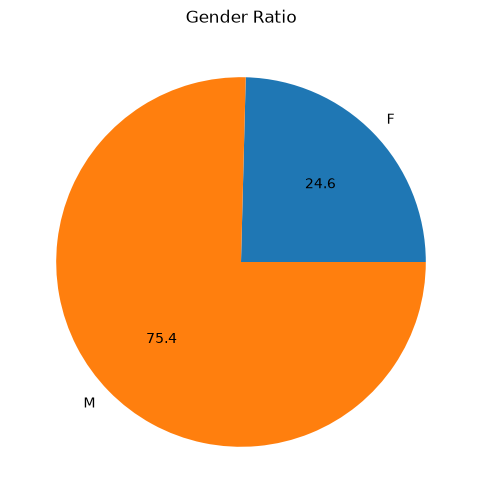

In [21]:
gender_ratio.plot(kind='pie', autopct="%.1f", title="Gender Ratio", figsize=(6,6))

<Axes: title={'center': 'Gender Ratio'}, xlabel='Gender'>

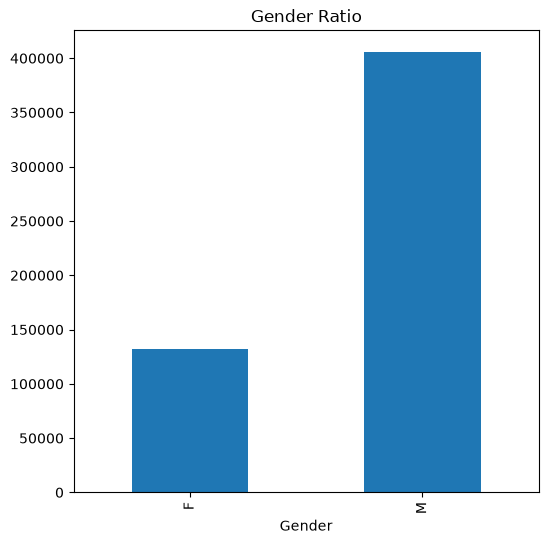

In [22]:
gender_ratio.plot(kind='bar', title="Gender Ratio", figsize=(6,6))

## 3.2 Total Purchase Amount by Gender

Calculate the combined purchase amount for each gender and compare their contributions to the total recorded purchase value.

Calculate the total purchase amount for each gender.

In [ ]:

df.groupby("Gender").sum()["Purchase"]

Gender
F    1164624021
M    3853044357
Name: Purchase, dtype: int64

<Axes: title={'center': 'Gender Ratio'}>

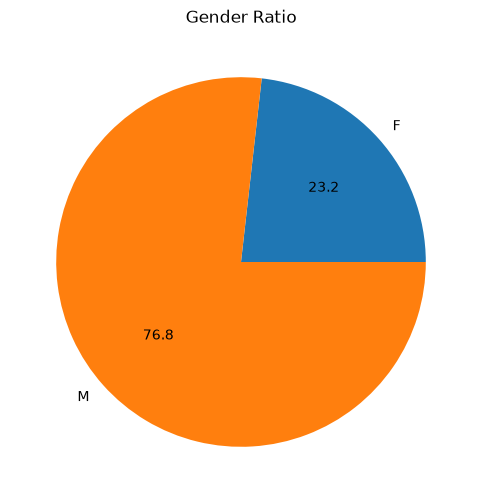

In [24]:
df.groupby("Gender").sum()["Purchase"].plot(kind='pie', autopct="%.1f", title="Gender Ratio", figsize=(6,6))

## 3.3 Average Purchase Amount by Gender

Calculate the average purchase amount for each gender. This compares the average value of a purchase record, rather than total spending.

In [53]:
df.groupby("Gender")["Purchase"].mean()

Gender
F    8809.761349
M    9504.771713
Name: Purchase, dtype: float64

<Axes: title={'center': 'Gender Ratio'}>

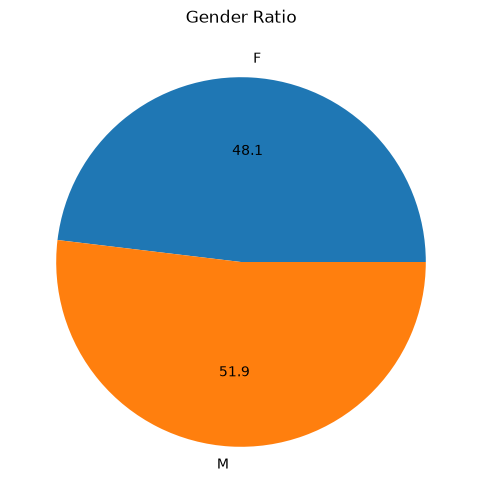

In [25]:
df.groupby("Gender")["Purchase"].mean().plot(kind='pie', autopct="%.1f", title="Gender Ratio", figsize=(6,6))

# 4. Age Group and Marital Status Analysis

Examine how purchase records and purchase amounts vary across age groups and marital-status categories.

## 4.1 Purchase Records by Age Group

Count the number of records in each age group and compare their distribution.

Count the number of purchase records in each age group.

In [ ]:
# Total no. of customer in each age group
df.groupby("Age").size()

Age
0-17      14707
18-25     97634
26-35    214690
36-45    107499
46-50     44526
51-55     37618
55+       20903
dtype: int64

<Axes: title={'center': 'Purchase Distribution by Age'}, xlabel='Age'>

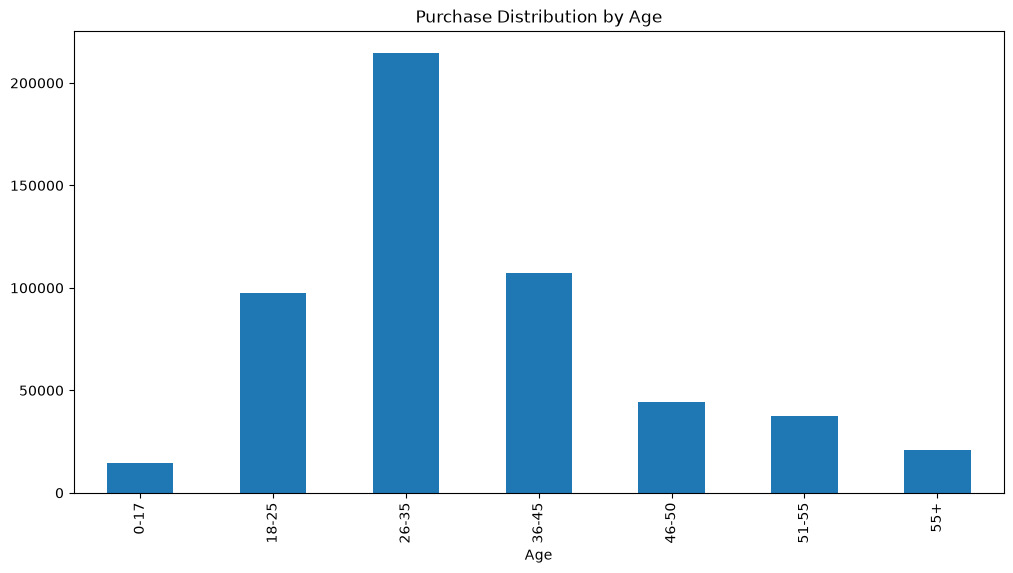

In [29]:
df.groupby("Age").size().plot(kind="bar", title="Purchase Distribution by Age", figsize=(12,6))

## 4.2 Purchase Records by Age Group

Count the purchase records associated with each age group. Each row represents a recorded purchase, not necessarily a distinct product.

Count the purchase records associated with each age group.

In [ ]:

for i in df["Age"].unique():
    print(i, " : ", len(df[df["Age"] == i]))

0-17  :  14707
55+  :  20903
26-35  :  214690
46-50  :  44526
51-55  :  37618
36-45  :  107499
18-25  :  97634


## 4.3 Distinct Products Purchased by Age Group

Count the number of unique `Product_ID` values associated with each age group. A product ID is counted once per age group, even if it appears in multiple records.

Build a table containing each age group and its number of distinct product IDs.

In [ ]:

lst = []

for i in df["Age"].unique():
    lst.append((i, df[df['Age'] == i]['Product_ID'].nunique()))

data = pd.DataFrame(lst, columns=["Age", "Columns"])
data

,Age,Columns
0,0-17,2300
1,55+,2573
2,26-35,3419
3,46-50,3099
4,51-55,2877
5,36-45,3318
6,18-25,3213


Visualize the number of distinct product IDs by age group.

<Axes: title={'center': 'Unique Product Purchase Distribution by Age'}, xlabel='Age'>

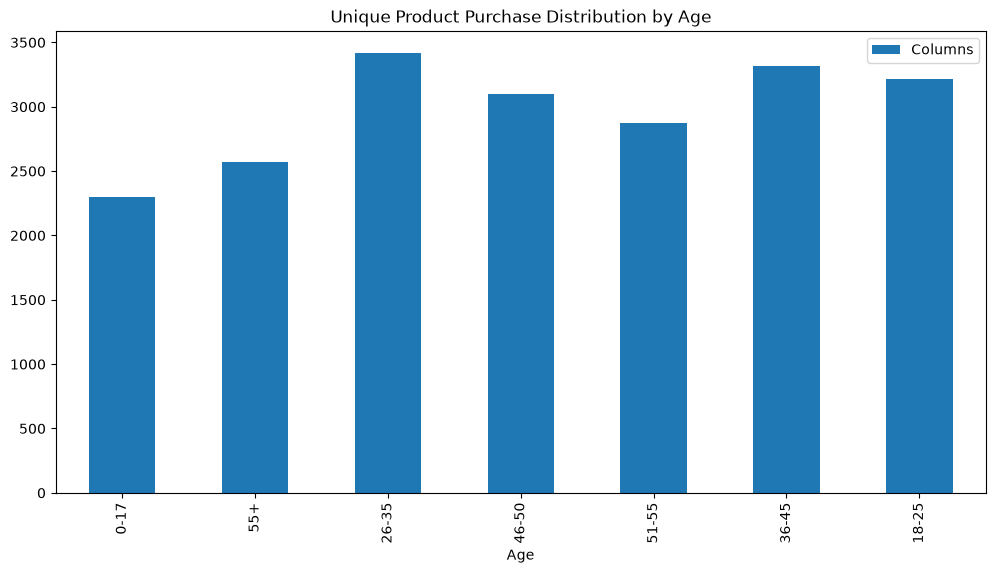

In [41]:
data.plot(kind="bar", title="Unique Product Purchase Distribution by Age", x="Age", figsize=(12,6))

## 4.4 Total Purchase Amount by Age Group

Sum the purchase amounts for each age group to compare their total recorded spending.

<Axes: title={'center': 'Amount Spend by Age'}, xlabel='Age'>

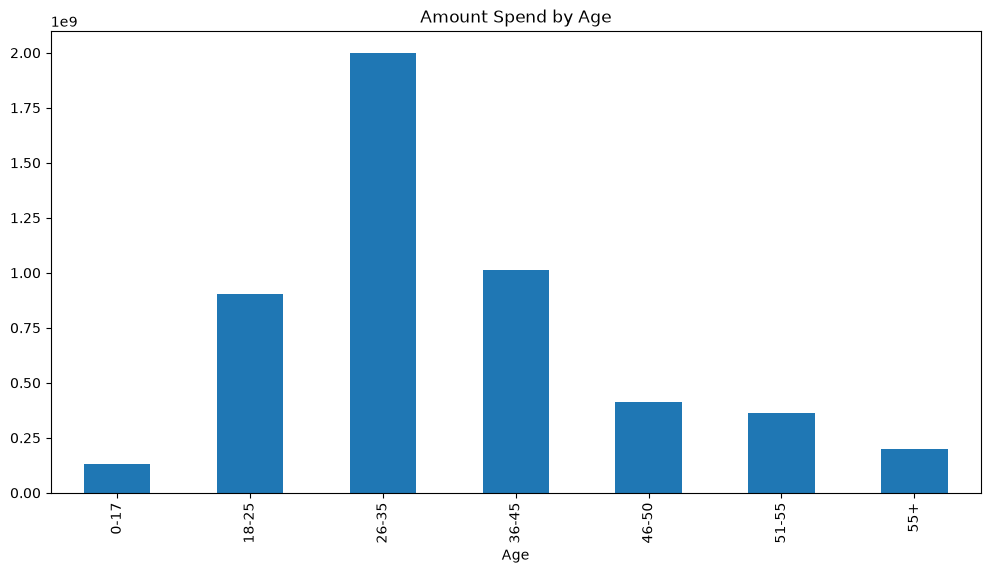

In [47]:
df.groupby("Age").sum()["Purchase"].plot(kind="bar", title="Amount Spend by Age", figsize=(12,6), x="Age", y="Purchase")

## 4.5 Average Purchase Amount by Age Group

Calculate the mean purchase amount for each age group to compare the average value of a purchase record.

Calculate the average purchase amount for each age group.

In [49]:
# Average price paid by Age
df.groupby("Age")["Purchase"].mean()

Age
0-17     9020.126878
18-25    9235.197575
26-35    9314.588970
36-45    9401.478758
46-50    9284.872277
51-55    9620.616620
55+      9453.898579
Name: Purchase, dtype: float64

<Axes: title={'center': 'Average price paid by Age'}>

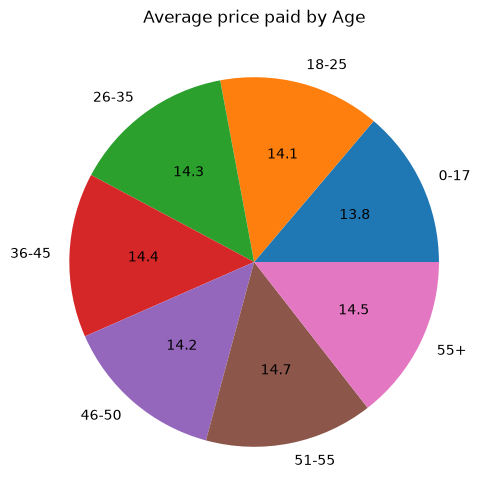

In [46]:
df.groupby("Age")["Purchase"].mean().plot(kind="pie", title="Average price paid by Age", figsize=(6,6), autopct="%.1f")

## 4.6 Purchase Records by Marital Status

Count the records for each marital-status category. In this dataset, `0` and `1` represent the available marital-status labels.

Count the purchase records for each marital-status category.

In [ ]:

df.groupby("Marital_Status")size()

Marital_Status
0    317817
1    219760
dtype: int64

<Axes: title={'center': 'Marital_Status'}>

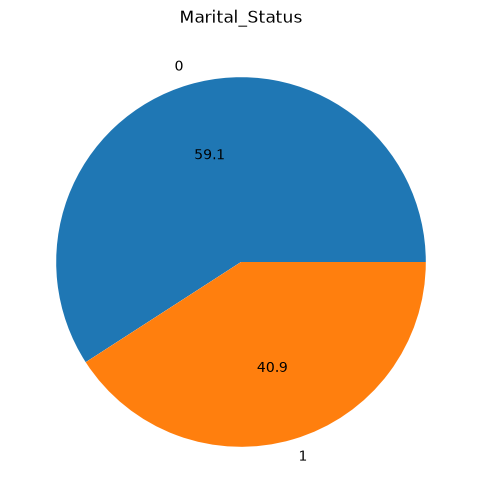

In [ ]:
df.groupby("Marital_Status").size().plot(kind="pie", title="Marital_Status", figsize=(6,6), autopct="%.1f")

# 5. Multi-Column Analysis

Explore combinations of customer attributes to compare purchase-record distributions across demographic groups.

## 5.1 Age Group and Gender

Compare the number of records across age groups, split by gender. These count plots show record frequency, not purchase amounts.

Compare record counts by age group, with separate bars for each gender.

<Axes: xlabel='Age', ylabel='count'>

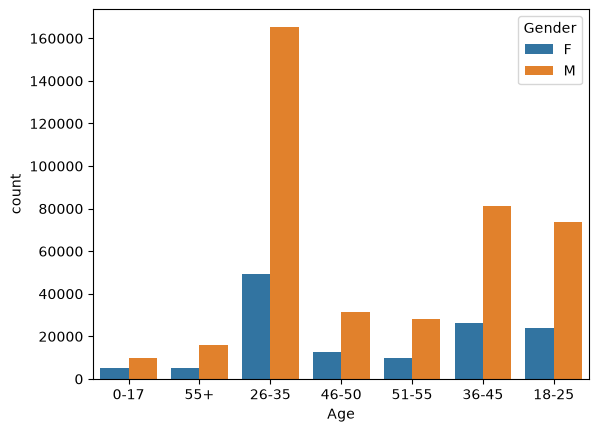

In [56]:
sns.countplot(x="Age", hue="Gender", data=df)

Compare record counts by gender, with separate bars for each age group.

<Axes: xlabel='Gender', ylabel='count'>

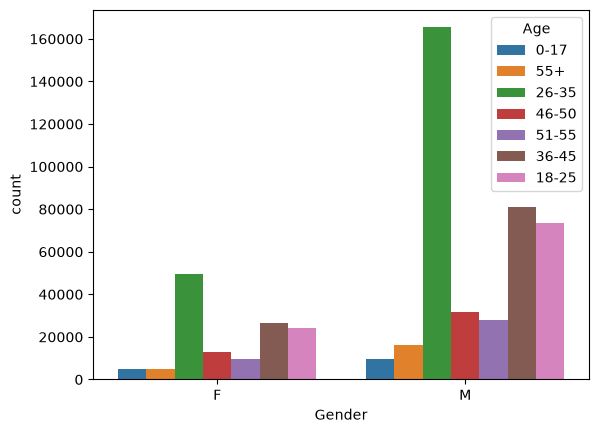

In [57]:
sns.countplot(x="Gender", hue="Age", data=df)

## 5.2 Gender and Marital Status

Compare purchase-record counts by gender and marital status to see how the groups are represented in the dataset.

Compare record counts by gender, split by marital status.

<Axes: xlabel='Gender', ylabel='count'>

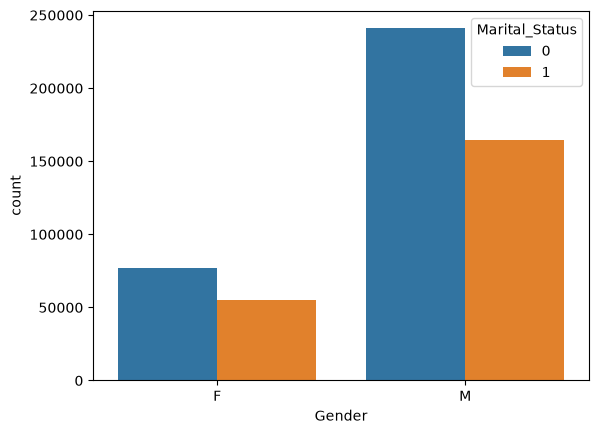

In [59]:
sns.countplot(x="Gender", hue="Marital_Status", data=df)

Compare record counts by marital status, split by gender.

<Axes: xlabel='Marital_Status', ylabel='count'>

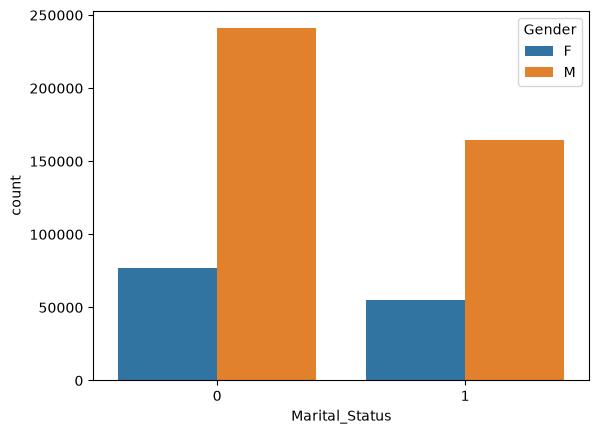

In [58]:
sns.countplot(x="Marital_Status", hue="Gender", data=df)


## 5.3 Purchase Records by City Category

Count records from each city category and compare their distribution.

Plot the number of records in each city category.

<Axes: xlabel='City_Category', ylabel='count'>

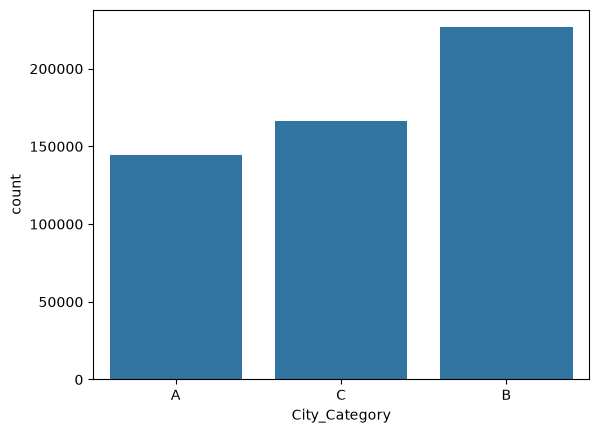

In [68]:
sns.countplot(x=df["City_Category"])

Show the proportion of records belonging to each city category.

<Axes: >

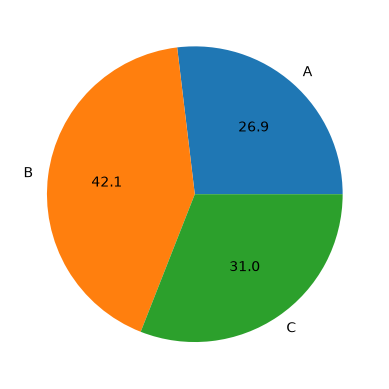

In [67]:
df.groupby("City_Category").size().plot.pie(autopct="%.1f")

## 5.4 City Category and Customer Demographics

Compare city categories by age group, marital status, and gender to examine differences in the composition of the recorded purchases.

Compare age-group record counts across city categories.

<Axes: xlabel='City_Category', ylabel='count'>

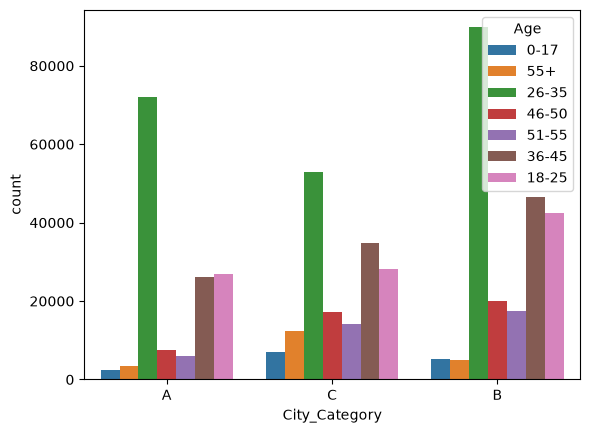

In [70]:
sns.countplot(x="City_Category", hue="Age", data=df)

Compare marital-status record counts across city categories.

<Axes: xlabel='City_Category', ylabel='count'>

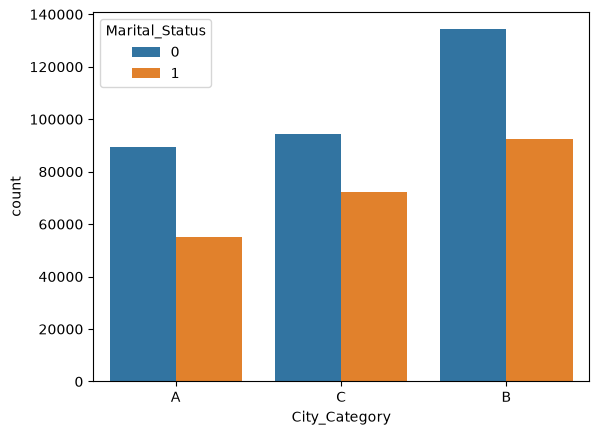

In [74]:
sns.countplot(x="City_Category", hue="Marital_Status", data=df)

Compare gender record counts across city categories.

<Axes: xlabel='City_Category', ylabel='count'>

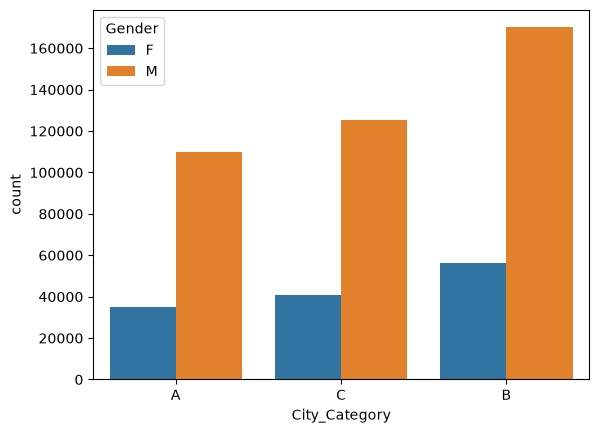

In [75]:
sns.countplot(x="City_Category", hue="Gender", data=df)

Calculate the total purchase amount for each city category.

In [76]:
df.groupby("City_Category").sum()["Purchase"]

City_Category
A    1295668797
B    2083431612
C    1638567969
Name: Purchase, dtype: int64

Compare total purchase amounts across city categories.

<Axes: title={'center': 'Total spending amount in each City'}, xlabel='City_Category'>

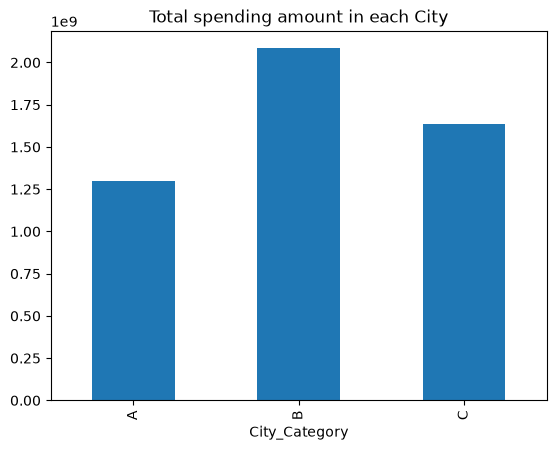

In [77]:
df.groupby("City_Category").sum()["Purchase"].plot(kind="bar", title="Total spending amount in each City")

Show each city category's share of the total recorded purchase amount.

<Axes: title={'center': 'Total spending amount in each City'}>

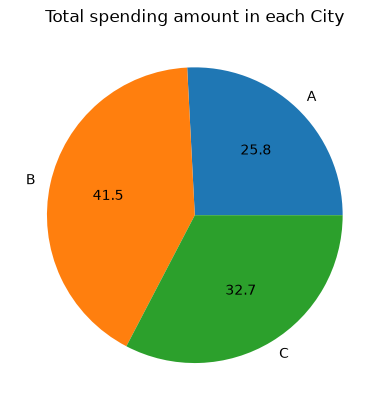

In [78]:
df.groupby("City_Category").sum()["Purchase"].plot(kind="pie", autopct="%.1f", title="Total spending amount in each City")

Calculate the average purchase amount for each city category.

In [79]:
df.groupby("City_Category")["Purchase"].mean()

City_Category
A    8958.011014
B    9198.657848
C    9844.441855
Name: Purchase, dtype: float64

Compare the average purchase amount across city categories.

<Axes: title={'center': 'Average spending amount in each City'}>

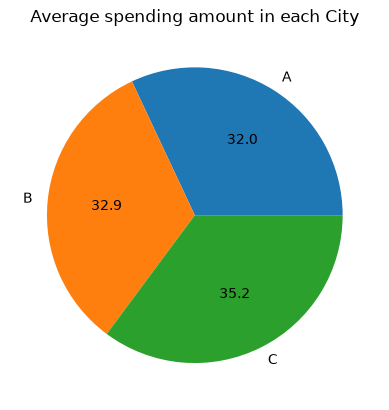

In [80]:
df.groupby("City_Category")["Purchase"].mean().plot(kind="pie", autopct="%.1f", title="Average spending amount in each City")

# 6. Customer Residence, Occupation, and Product Analysis

Explore how length of residence in the current city and occupation relate to purchase-record counts and purchase amounts.

## 6.1 Records by Years in Current City

Examine how many purchase records are associated with customers who have lived in their current city for different lengths of time.

Count purchase records by the number of years customers have lived in their current city.

<Axes: xlabel='Stay_In_Current_City_Years', ylabel='count'>

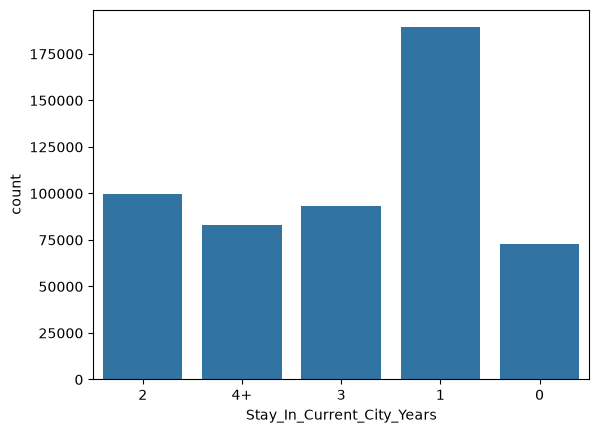

In [84]:
sns.countplot(x=df["Stay_In_Current_City_Years"])

Visualize the proportion of records by years in the current city.

<Axes: >

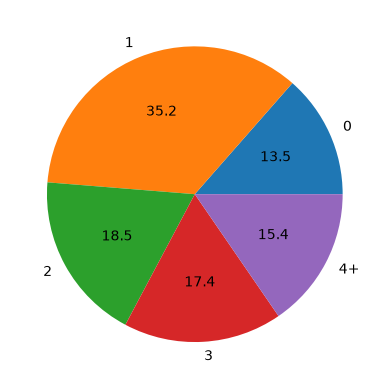

In [88]:
df.groupby("Stay_In_Current_City_Years").size().plot(kind="pie", autopct="%.1f")

Calculate the total purchase amount for each residence-duration category.

In [89]:
df.groupby("Stay_In_Current_City_Years")["Purchase"].sum()

Stay_In_Current_City_Years
0      672505429
1     1763243917
2      934676626
3      872531130
4+     774711276
Name: Purchase, dtype: int64

Compare total purchase amounts by years in the current city.

<Axes: xlabel='Stay_In_Current_City_Years'>

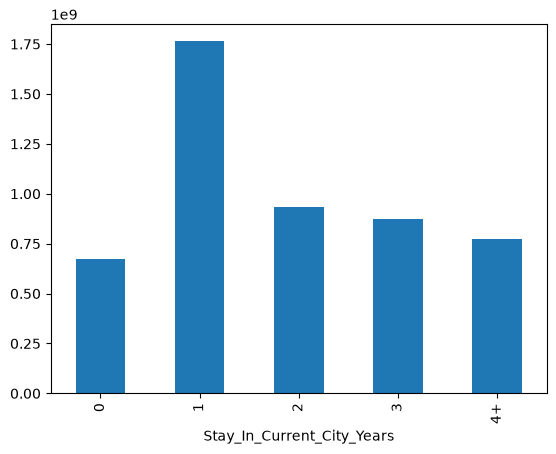

In [91]:
df.groupby("Stay_In_Current_City_Years")["Purchase"].sum().plot.bar()

Calculate the average purchase amount for each residence-duration category.

In [ ]:
df.groupby("Stay_In_Current_City_Years")["Purchase"].mean()

Stay_In_Current_City_Years
0     9247.238625
1     9319.865095
2     9397.607316
3     9350.685121
4+    9346.370158
Name: Purchase, dtype: float64

Compare average purchase amounts by years in the current city.

<Axes: >

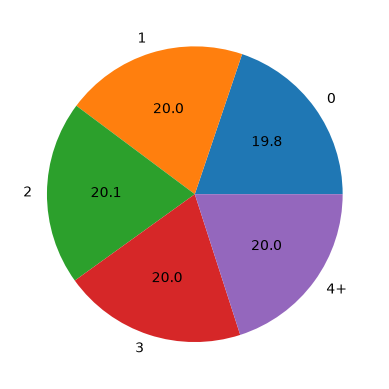

In [96]:
df.groupby("Stay_In_Current_City_Years")["Purchase"].mean().plot(kind="pie",autopct="%.1f")

Compare residence-duration record counts by gender.

<Axes: xlabel='Stay_In_Current_City_Years', ylabel='count'>

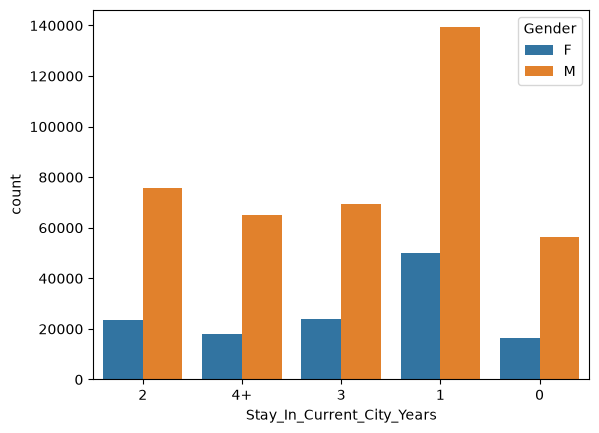

In [83]:
sns.countplot(x=df["Stay_In_Current_City_Years"], hue=df["Gender"])

Compare residence-duration record counts by marital status.

<Axes: xlabel='Stay_In_Current_City_Years', ylabel='count'>

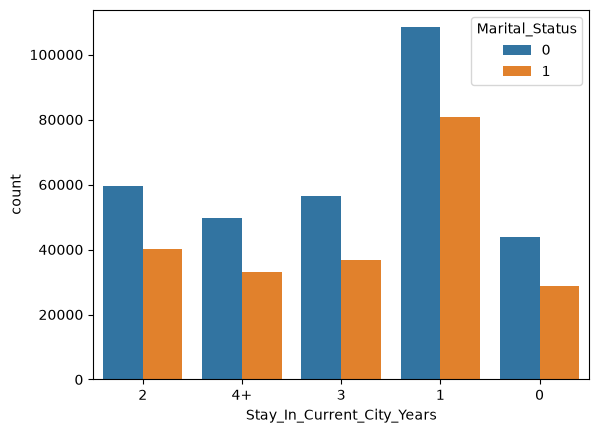

In [85]:
sns.countplot(x=df["Stay_In_Current_City_Years"], hue=df["Marital_Status"])

Compare residence-duration record counts by city category.

<Axes: xlabel='Stay_In_Current_City_Years', ylabel='count'>

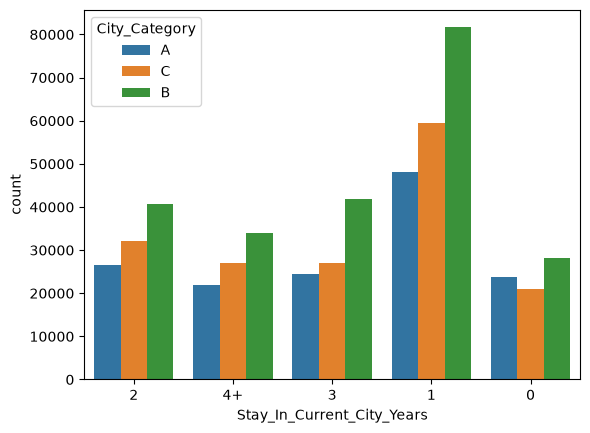

In [86]:
sns.countplot(x=df["Stay_In_Current_City_Years"], hue=df["City_Category"])

## 6.2 Age Group by City Category

Compare the distribution of age groups across city categories using purchase-record counts.

Compare age-group record counts across city categories.

<Axes: xlabel='City_Category', ylabel='count'>

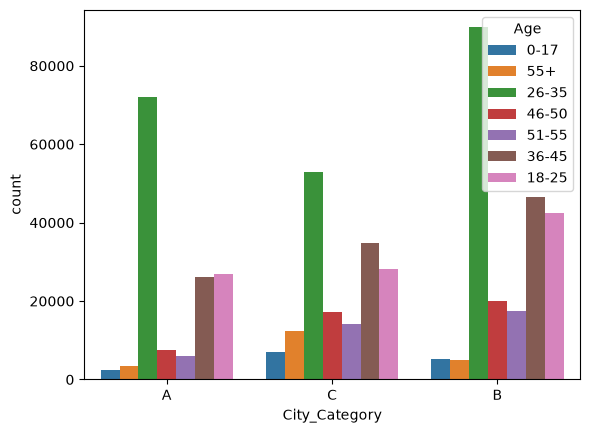

In [87]:
sns.countplot(hue=df["Age"], x=df["City_Category"])

## 6.3 Occupation Analysis

Analyze the number of purchase records and purchase amounts across occupation categories.

Visualize the number of records in each occupation category.

<Axes: xlabel='Occupation', ylabel='count'>

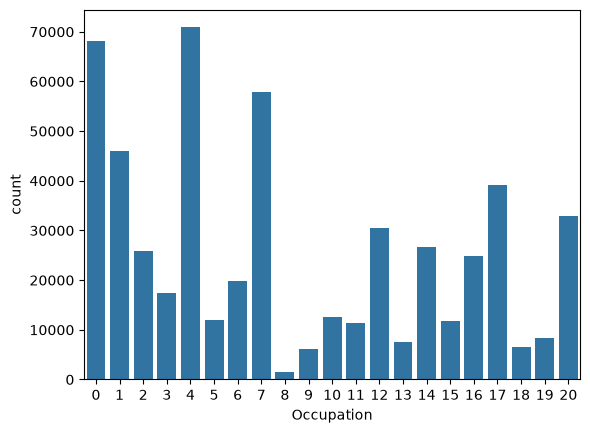

In [101]:
sns.countplot(x=df['Occupation'])

Count purchase records by occupation.

In [102]:
df.groupby("Occupation").size()

Occupation
0     68120
1     45971
2     25845
3     17366
4     70862
5     11985
6     19822
7     57806
8      1524
9      6153
10    12623
11    11338
12    30423
13     7548
14    26712
15    11812
16    24790
17    39090
18     6525
19     8352
20    32910
dtype: int64

Sort occupation categories by record count and visualize the comparison.

<Axes: xlabel='Occupation'>

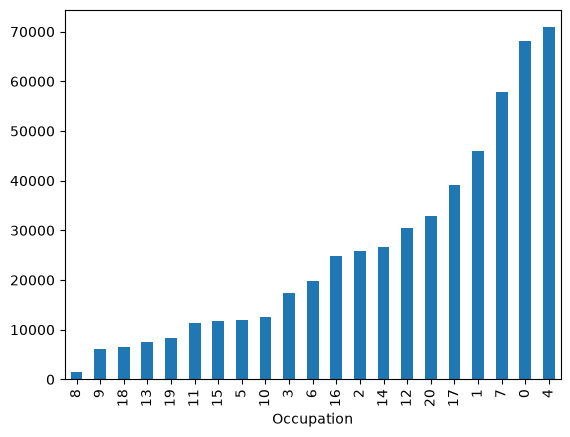

In [103]:
df.groupby("Occupation").size().sort_values().plot(kind="bar")

Calculate total purchase amount by occupation and sort the results.

In [110]:
df.groupby("Occupation").sum()["Purchase"].sort_values()

Occupation
8      14594599
9      53619309
18     60249706
13     71135744
19     73115489
11    105437359
5     112525355
10    114273954
15    116540026
3     160428450
6     185065697
2     233275393
16    234442330
14    255594745
20    292276985
12    300672105
17    387240355
1     414552829
7     549282744
0     625814811
4     657530393
Name: Purchase, dtype: int64

Visualize total purchase amounts by occupation.

<Axes: xlabel='Occupation'>

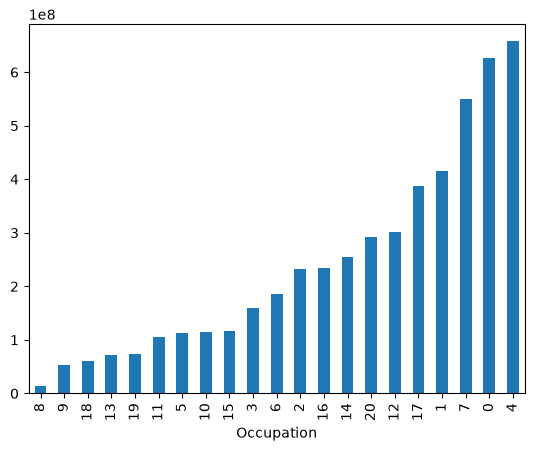

In [105]:
df.groupby("Occupation").sum()["Purchase"].sort_values().plot(kind="bar")

Calculate average purchase amount by occupation and sort the results.

In [109]:
df.groupby("Occupation")["Purchase"].mean().sort_values()

Occupation
9     8714.335934
19    8754.249162
20    8881.099514
1     9017.703095
2     9025.938982
10    9052.836410
0     9186.946726
18    9233.671418
3     9238.077277
4     9279.026742
11    9299.467190
6     9336.378620
5     9388.848978
13    9424.449391
16    9457.133118
7     9502.175276
14    9568.536426
8     9576.508530
15    9866.239925
12    9883.052460
17    9906.378997
Name: Purchase, dtype: float64

Visualize average purchase amounts by occupation.

<Axes: xlabel='Occupation'>

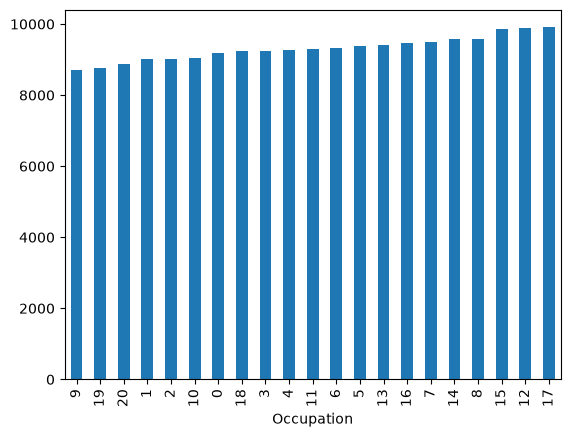

In [107]:
df.groupby("Occupation")["Purchase"].mean().sort_values().plot(kind="bar")

Compare occupation record counts by marital status.

<Axes: xlabel='Occupation', ylabel='count'>

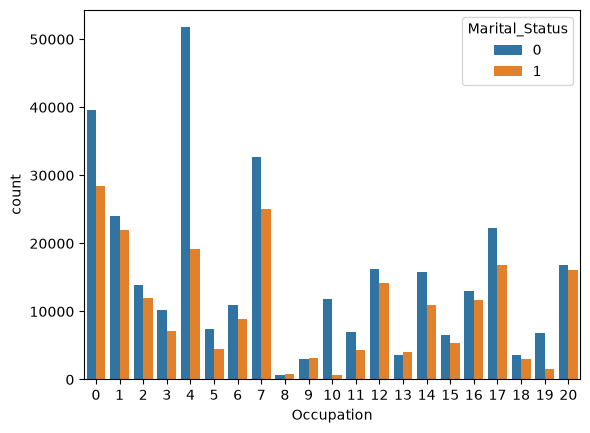

In [111]:
sns.countplot(x="Occupation", hue="Marital_Status", data=df)

Compare occupation record counts by gender.

<Axes: xlabel='Occupation', ylabel='count'>

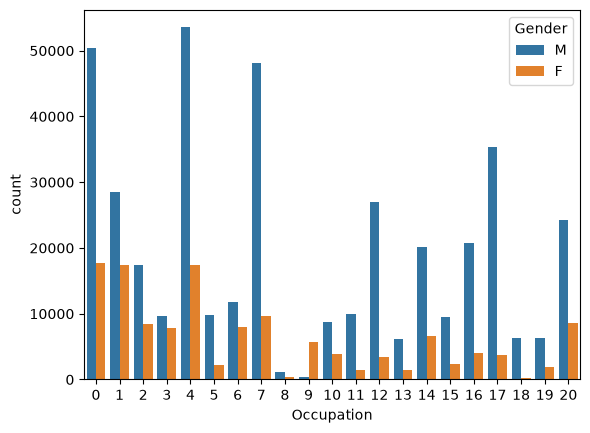

In [112]:
sns.countplot(x="Occupation", hue="Gender", data=df)

## 6.4 Distinct Products by Occupation

Count the unique product IDs associated with each occupation category. This measures product variety in the records, not the total number of transactions.

Count the distinct product IDs associated with each occupation.

In [115]:
df.groupby("Occupation").nunique()["Product_ID"]

Occupation
0     3243
1     3020
2     2892
3     2657
4     3174
5     2344
6     2724
7     3070
8     1026
9     1820
10    2110
11    2235
12    2664
13    1946
14    2680
15    2168
16    2863
17    2831
18    2047
19    2303
20    3147
Name: Product_ID, dtype: int64

Visualize the number of distinct product IDs by occupation.

<Axes: xlabel='Occupation'>

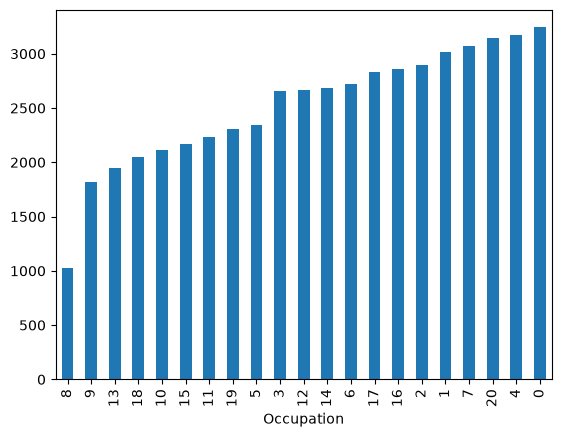

In [117]:
df.groupby("Occupation").nunique()["Product_ID"].sort_values().plot.bar()

## 6.5 Product Category Analysis

Examine record counts and total purchase amounts for each value of `Product_Category_1`.

Count records for each primary product category.

In [119]:
df.groupby("Product_Category_1").size()

Product_Category_1
1     138353
2      23499
3      19849
4      11567
5     148592
6      20164
7       3668
8     112132
9        404
10      5032
11     23960
12      3875
13      5440
14      1500
15      6203
16      9697
17       567
18      3075
dtype: int64

Visualize record counts by primary product category.

<Axes: xlabel='Product_Category_1'>

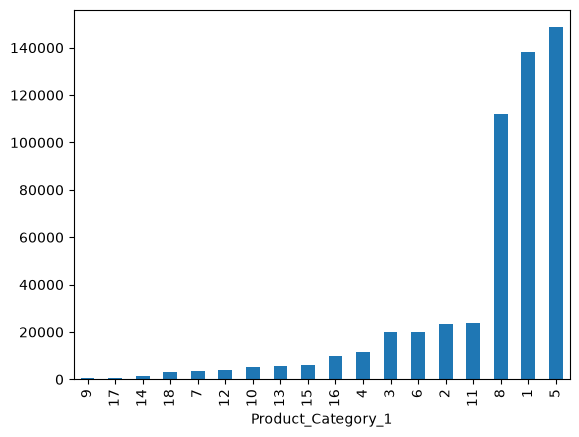

In [120]:
df.groupby("Product_Category_1").size().sort_values().plot.bar()

Calculate total purchase amount by primary product category.

In [122]:
df.groupby("Product_Category_1").sum()["Purchase"]

Product_Category_1
1     1882666325
2      264497242
3      200412211
4       26937957
5      926917497
6      319355286
7       60059209
8      840693394
9        6277472
10      99029631
11     112203088
12       5235883
13       3931050
14      19718178
15      91658147
16     143168035
17       5758702
18       9149071
Name: Purchase, dtype: int64

Visualize total purchase amounts by primary product category.

<Axes: xlabel='Product_Category_1'>

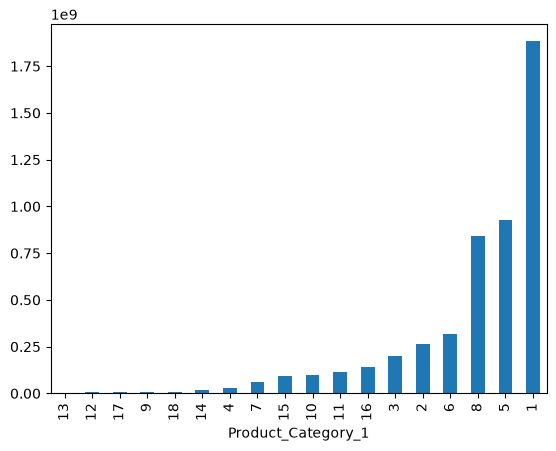

In [123]:
df.groupby("Product_Category_1").sum()['Purchase'].sort_values().plot.bar()

# 7. Product-Level Analysis

Identify products with high total purchase amounts, frequent purchase records, and high average purchase amounts.

## 7.1 Top 10 Products by Total Purchase Amount

Rank products by the sum of their recorded purchase amounts. These products have the highest total purchase value in this dataset.

Calculate the ten product IDs with the highest total purchase amount.

In [135]:
df.groupby("Product_ID").sum()['Purchase'].nlargest(10).sort_values(ascending=False)

Product_ID
P00025442    27532426
P00110742    26382569
P00255842    24652442
P00184942    24060871
P00059442    23948299
P00112142    23882624
P00110942    23232538
P00237542    23096487
P00057642    22493690
P00010742    21865042
Name: Purchase, dtype: int64

Visualize the top ten products by total purchase amount.

<Axes: title={'center': 'Hot Selling Products'}, xlabel='Product_ID'>

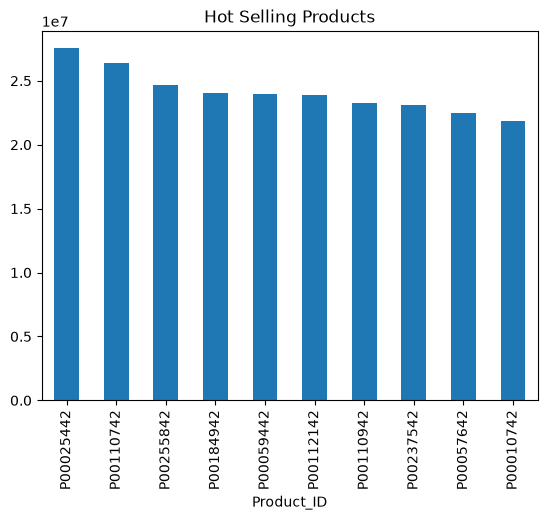

In [136]:
df.groupby("Product_ID").sum()['Purchase'].nlargest(10).sort_values(ascending=False).plot.bar(title="Hot Selling Products")

## 7.2 Top 10 Products by Number of Records

Rank products by how often their product IDs appear in the dataset. The count represents purchase records, not necessarily unique customers.

Count how often each product ID appears and select the ten most frequent.

In [134]:
df.groupby("Product_ID").size().nlargest(10).sort_values(ascending=False)

Product_ID
P00265242    1858
P00110742    1591
P00025442    1586
P00112142    1539
P00057642    1430
P00184942    1424
P00046742    1417
P00058042    1396
P00059442    1384
P00145042    1384
dtype: int64

Visualize the ten most frequently recorded product IDs.

<Axes: title={'center': 'Most Purchased Products'}, xlabel='Product_ID'>

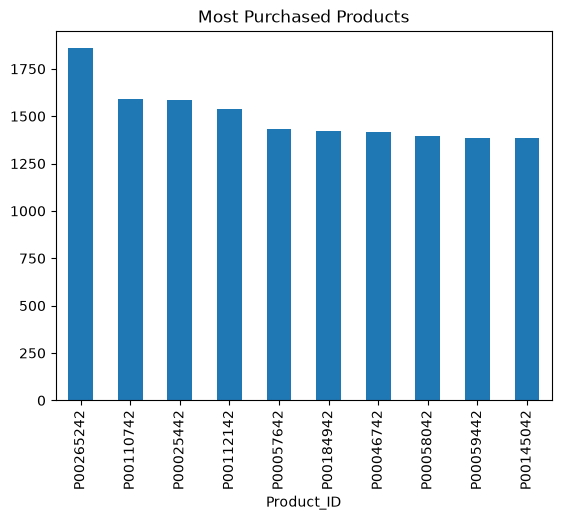

In [137]:
df.groupby("Product_ID").size().nlargest(10).sort_values(ascending=False).plot.bar(title="Most Purchased Products")

## 7.3 Average Purchase Amount by Product

Calculate the average recorded purchase amount for each product ID.

Calculate the average purchase amount for every product ID and sort the results.

In [141]:
df.groupby("Product_ID")["Purchase"].mean().sort_values(ascending=False)

Product_ID
P00086242    21297.865672
P00085342    20993.804428
P00200642    20479.229885
P00116142    20478.264753
P00119342    20454.296053
                 ...     
P00273842      524.666667
P00063242      498.000000
P00293442      478.500000
P00041442      455.540816
P00091742      405.000000
Name: Purchase, Length: 3623, dtype: float64

## 7.4 Top 10 Products by Average Purchase Amount

Display the ten product IDs with the highest mean purchase amount among their recorded purchases.

Select the ten product IDs with the highest average purchase amount.

In [140]:
df.groupby("Product_ID")["Purchase"].mean().nlargest(10).sort_values(ascending=False)

Product_ID
P00086242    21297.865672
P00085342    20993.804428
P00200642    20479.229885
P00116142    20478.264753
P00119342    20454.296053
P00117642    20453.368557
P00074542    20323.000000
P00341542    20291.000000
P00052842    20136.811983
P00087042    20079.646809
Name: Purchase, dtype: float64

Visualize the ten products with the highest average purchase amount.

<Axes: xlabel='Product_ID'>

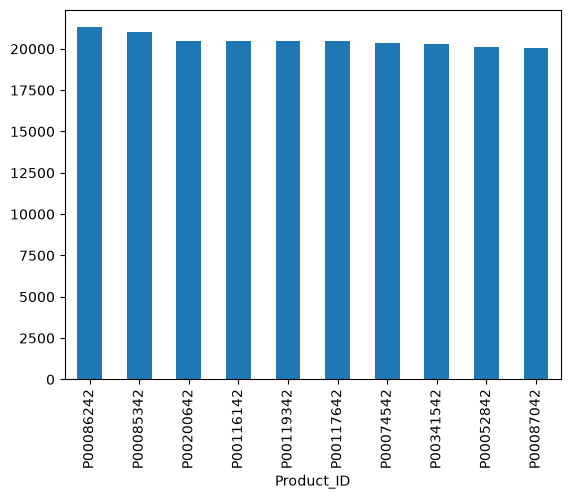

In [142]:
df.groupby("Product_ID")["Purchase"].mean().nlargest(10).sort_values(ascending=False).plot.bar()

# 8. Combined Gender and Marital Status Analysis

Create a combined category from gender and marital status, then compare record counts across age groups, product categories, residence duration, and city categories.

Create a combined label using gender and marital status for each row. This enables comparisons of the combined groups in the following charts.

In [143]:
l=[]
for i in range(len(df)):
    l.append(df['Gender'][i] +"_"+ str(df['Marital_Status'][i]))

df['Marital_Gender'] = l

Preview the DataFrame to verify that the combined column was added.

In [ ]:
df.head()

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Purchase,Marital_Gender
0,1000001,P00069042,F,0-17,10,A,2,0,3,8370,F_0
1,1000001,P00248942,F,0-17,10,A,2,0,1,15200,F_0
2,1000001,P00087842,F,0-17,10,A,2,0,12,1422,F_0
3,1000001,P00085442,F,0-17,10,A,2,0,12,1057,F_0
4,1000002,P00285442,M,55+,16,C,4+,0,8,7969,M_0


Compare the number of records in each gender and marital-status group.

<Axes: xlabel='Marital_Gender', ylabel='count'>

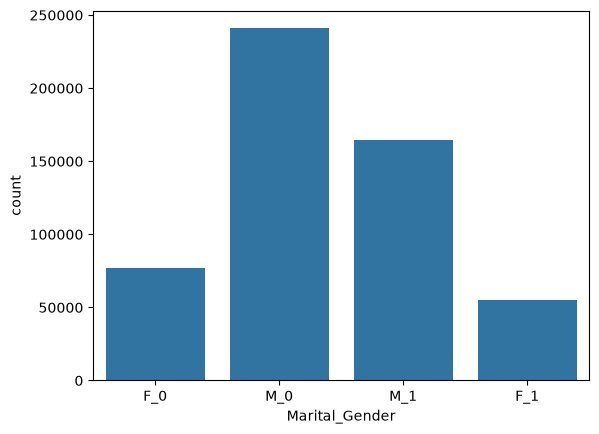

In [149]:
sns.countplot(x="Marital_Gender",  data=df)

Compare age-group record counts across the combined gender and marital-status groups.

<Axes: xlabel='Age', ylabel='count'>

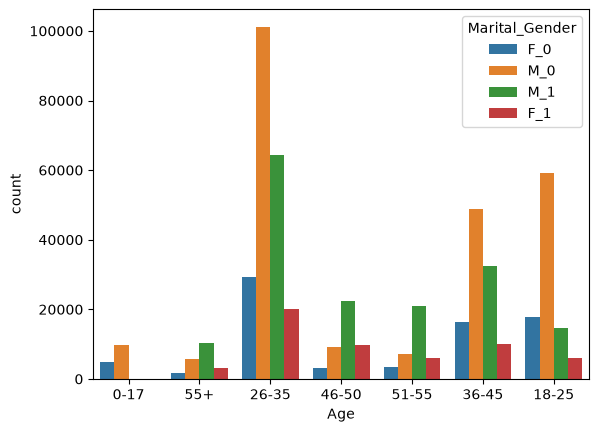

In [150]:
sns.countplot(x="Age", hue="Marital_Gender",  data=df)

Compare primary product-category record counts across the combined groups.

<Axes: xlabel='Product_Category_1', ylabel='count'>

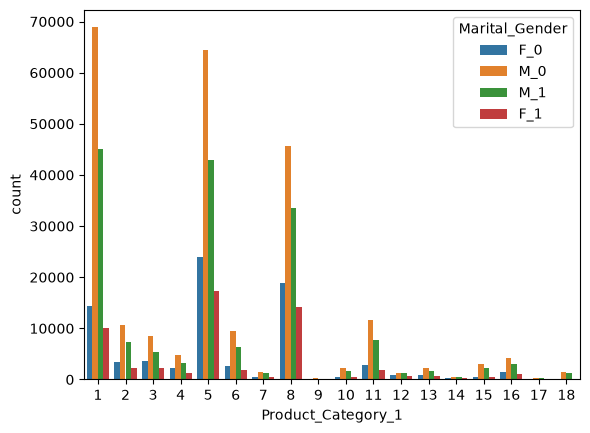

In [151]:
sns.countplot(x="Product_Category_1", hue="Marital_Gender",  data=df)

Compare residence-duration record counts across the combined groups.

<Axes: xlabel='Stay_In_Current_City_Years', ylabel='count'>

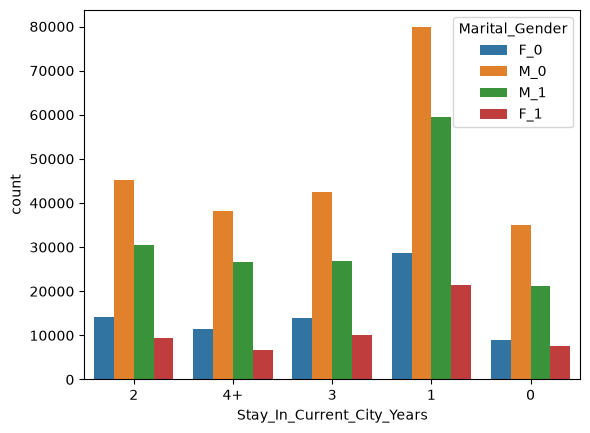

In [152]:
sns.countplot(x="Stay_In_Current_City_Years", hue="Marital_Gender",  data=df)

Compare city-category record counts across the combined groups.

<Axes: xlabel='City_Category', ylabel='count'>

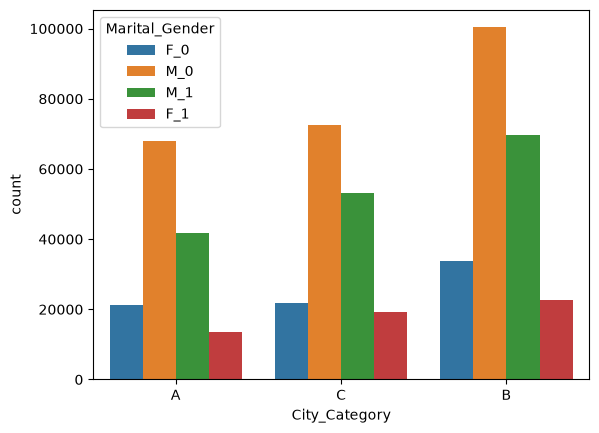

In [153]:
sns.countplot(x="City_Category", hue="Marital_Gender",  data=df)

## 9. Summary

This notebook explored the Black Friday sales dataset through dataset inspection, demographic analysis, city and occupation comparisons, and product-level analysis. The results describe patterns in the recorded transactions; they should not be treated as proof of customer behavior beyond what this dataset supports.